<a href="https://colab.research.google.com/github/Bassma-Chemaou/projet6-3d/blob/main/notebooks/02_baseline_autoencodeur.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
from google.colab import drive
drive.mount("/content/drive")

import numpy as np, torch, time, random
from pathlib import Path

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
dev = torch.device("cuda")
total_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
torch.cuda.set_per_process_memory_fraction(min(1.0, 12 / total_gb))   # limite 12 Go

D = Path("/content/drive/MyDrive/projet6-3d/processed")
CK = Path("/content/drive/MyDrive/projet6-3d/checkpoints"); CK.mkdir(parents=True, exist_ok=True)

cats = (D / "categories.txt").read_text().split("\n")
X = {s: torch.from_numpy(np.load(D / f"points_{s}.npy")) for s in ["train", "val", "test"]}
Y = {s: np.load(D / f"labels_{s}.npy") for s in ["train", "val", "test"]}
print({s: tuple(X[s].shape) for s in X}, "| GPU :", torch.cuda.get_device_name(0))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{'train': (1353, 2048, 3), 'val': (239, 2048, 3), 'test': (400, 2048, 3)} | GPU : Tesla T4


In [9]:
def chamfer_batch(a, b):
    """a, b : (B, N, 3) -> distance de Chamfer au carré, une valeur par paire (B,)."""
    d = torch.cdist(a, b)
    return d.min(2)[0].pow(2).mean(1) + d.min(1)[0].pow(2).mean(1)

@torch.no_grad()
def pairwise_cd(A, B, chunk=50):
    """Matrice (len(A), len(B)) des distances de Chamfer."""
    A, B = A.to(dev), B.to(dev)
    out = torch.zeros(len(A), len(B))
    for i in range(len(A)):
        a = A[i:i + 1]
        for j in range(0, len(B), chunk):
            b = B[j:j + chunk]
            out[i, j:j + chunk] = chamfer_batch(a.expand(len(b), -1, -1).contiguous(), b).cpu()
    return out

def gen_metrics(G, R):
    """G : formes générées, R : formes réelles de référence (mêmes effectifs)."""
    M_rg, M_rr, M_gg = pairwise_cd(R, G), pairwise_cd(R, R), pairwise_cd(G, G)
    mmd = M_rg.min(1)[0].mean().item()                          # qualité (plus bas = mieux)
    cov = len(torch.unique(M_rg.argmin(0))) / len(R)            # diversité (plus haut = mieux)
    big = torch.cat([torch.cat([M_rr, M_rg], 1), torch.cat([M_rg.t(), M_gg], 1)], 0)
    big.fill_diagonal_(float("inf"))                            # un point n'est pas son propre voisin
    lab = torch.cat([torch.ones(len(R)), torch.zeros(len(G))])
    nna = (lab[big.argmin(1)] == lab).float().mean().item()     # idéal : proche de 0.5
    return {"MMD-CD": mmd, "COV": cov, "1-NNA": nna}

In [10]:
NP = 1024   # 1 024 points pour les métriques : 4 fois plus rapide
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(X["train"]), generator=g)[:len(X["test"])]
G_ref = X["train"][idx][:, :NP]      # "formes générées" = copies de formes du train
R = X["test"][:, :NP]                # formes réelles de référence

t0 = time.time()
ref = gen_metrics(G_ref, R)
print("Référence train/test :", {k: round(v, 4) for k, v in ref.items()}, f"({time.time()-t0:.0f} s)")

Référence train/test : {'MMD-CD': 0.0151, 'COV': 0.545, '1-NNA': 0.5525} (64 s)


In [11]:
import torch.nn as nn

class PointNetAE(nn.Module):
    def __init__(self, n_points=2048, latent=128):
        super().__init__()
        ch, layers = [3, 64, 128, 256, 512], []
        for i in range(4):
            layers += [nn.Conv1d(ch[i], ch[i + 1], 1), nn.BatchNorm1d(ch[i + 1]), nn.ReLU()]
        self.enc = nn.Sequential(*layers)
        self.fc = nn.Linear(512, latent)
        self.dec = nn.Sequential(nn.Linear(latent, 512), nn.ReLU(),
                                 nn.Linear(512, 1024), nn.ReLU(),
                                 nn.Linear(1024, n_points * 3))
        self.n = n_points
    def forward(self, x):                                   # x : (B, N, 3)
        z = self.fc(self.enc(x.transpose(1, 2)).max(2)[0])  # max-pooling sur les points
        return self.dec(z).view(-1, self.n, 3), z

def augment(x, rot_deg=15, noise=0.01):
    """Petite rotation autour de l'axe vertical Z + bruit gaussien."""
    B = x.shape[0]
    th = (torch.rand(B, device=x.device) * 2 - 1) * rot_deg * np.pi / 180
    c, s = torch.cos(th), torch.sin(th)
    Rz = torch.zeros(B, 3, 3, device=x.device)
    Rz[:, 0, 0], Rz[:, 0, 1], Rz[:, 1, 0], Rz[:, 1, 1], Rz[:, 2, 2] = c, -s, s, c, 1
    return x @ Rz.transpose(1, 2) + noise * torch.randn_like(x)

@torch.no_grad()
def eval_cd(model, Xs, bs=64):
    model.eval(); tot = 0
    for i in range(0, len(Xs), bs):
        xb = Xs[i:i + bs].to(dev)
        tot += chamfer_batch(model(xb)[0], xb).sum().item()
    return tot / len(Xs)

EPOCHS, BS, LR = 200, 32, 1e-3
model = PointNetAE(2048, 128).to(dev)
n_params = sum(p.numel() for p in model.parameters())
opt = torch.optim.Adam(model.parameters(), lr=LR)
hist, best = {"train": [], "val": []}, 1e9
torch.cuda.reset_peak_memory_stats(); t0 = time.time()

for ep in range(1, EPOCHS + 1):
    model.train(); perm = torch.randperm(len(X["train"])); tot = 0
    for i in range(0, len(perm), BS):
        xb = X["train"][perm[i:i + BS]].to(dev)
        if len(xb) < 2: continue                            # BatchNorm exige au moins 2 éléments
        xb = augment(xb)
        loss = chamfer_batch(model(xb)[0], xb).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        tot += loss.item() * len(xb)
    tr, va = tot / len(perm), eval_cd(model, X["val"])
    hist["train"].append(tr); hist["val"].append(va)
    if va < best:                                           # meilleur checkpoint selon la validation
        best = va; torch.save(model.state_dict(), CK / "ae_baseline_best.pth")
    if ep % 10 == 0 or ep == 1:
        print(f"époque {ep:3d} | train {tr:.5f} | val {va:.5f} | meilleur {best:.5f} | {time.time()-t0:.0f} s")

train_time = time.time() - t0
vram = torch.cuda.max_memory_allocated() / 1e9
print(f"\nParamètres : {n_params:,} | durée : {train_time/60:.1f} min | VRAM max : {vram:.2f} Go")

époque   1 | train 0.05235 | val 0.02832 | meilleur 0.02832 | 4 s
époque  10 | train 0.01637 | val 0.01590 | meilleur 0.01283 | 41 s
époque  20 | train 0.01036 | val 0.00959 | meilleur 0.00945 | 81 s
époque  30 | train 0.00945 | val 0.00999 | meilleur 0.00925 | 121 s
époque  40 | train 0.00796 | val 0.00928 | meilleur 0.00855 | 162 s
époque  50 | train 0.00865 | val 0.00993 | meilleur 0.00835 | 202 s
époque  60 | train 0.00781 | val 0.00942 | meilleur 0.00810 | 242 s
époque  70 | train 0.00745 | val 0.00819 | meilleur 0.00810 | 282 s
époque  80 | train 0.00875 | val 0.00836 | meilleur 0.00771 | 323 s
époque  90 | train 0.00659 | val 0.00769 | meilleur 0.00745 | 363 s
époque 100 | train 0.00670 | val 0.00750 | meilleur 0.00745 | 403 s
époque 110 | train 0.00656 | val 0.00739 | meilleur 0.00739 | 443 s
époque 120 | train 0.00634 | val 0.00852 | meilleur 0.00739 | 483 s
époque 130 | train 0.00639 | val 0.00771 | meilleur 0.00739 | 523 s
époque 140 | train 0.00582 | val 0.00733 | meilleur 

Chamfer test (AE baseline) : 0.00684


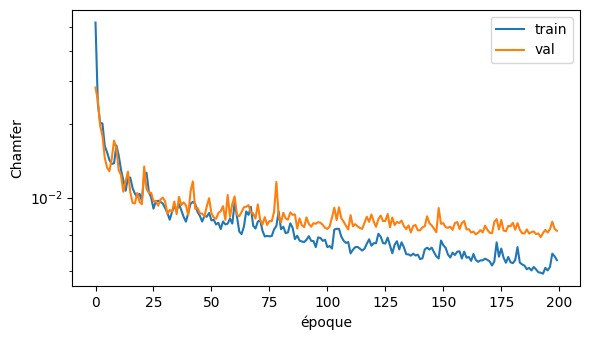

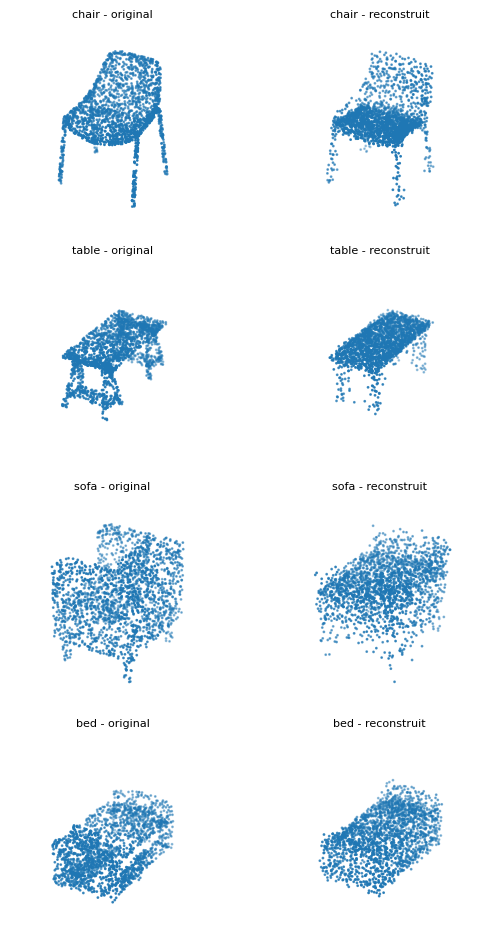

              Modèle Latent  Points  CD test    Params  Durée (min)  VRAM max (Go)  MMD-CD   COV  1-NNA
         AE PointNet    128    2048 0.006835 7129728.0         13.4           2.36     NaN   NaN    NaN
Référence train/test      -    1024      NaN       NaN          NaN            NaN  0.0151 0.545 0.5525


In [12]:
import matplotlib.pyplot as plt, pandas as pd

model.load_state_dict(torch.load(CK / "ae_baseline_best.pth")); model.eval()
cd_test = eval_cd(model, X["test"])
print(f"Chamfer test (AE baseline) : {cd_test:.5f}")

plt.figure(figsize=(6, 3.5))
plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.yscale("log"); plt.xlabel("époque"); plt.ylabel("Chamfer"); plt.legend(); plt.tight_layout(); plt.show()

fig = plt.figure(figsize=(6, 2.4 * len(cats)))
for r in range(len(cats)):
    i = int(np.where(Y["test"] == r)[0][0])
    x = X["test"][i:i + 1].to(dev)
    with torch.no_grad(): rec = model(x)[0]
    for k, (arr, nom) in enumerate([(x[0], "original"), (rec[0], "reconstruit")]):
        ax = fig.add_subplot(len(cats), 2, 2 * r + k + 1, projection="3d")
        p = arr.cpu().numpy(); ax.scatter(p[:, 0], p[:, 1], p[:, 2], s=1)
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
        ax.set_box_aspect((1, 1, 1)); ax.set_axis_off(); ax.set_title(f"{cats[r]} - {nom}", fontsize=8)
plt.tight_layout(); plt.show()

res = pd.DataFrame([{"Modèle": "AE PointNet", "Latent": 128, "Points": 2048, "CD test": cd_test,
                     "Params": n_params, "Durée (min)": round(train_time / 60, 1), "VRAM max (Go)": round(vram, 2)},
                    {"Modèle": "Référence train/test", "Latent": "-", "Points": NP, **{k: round(v, 4) for k, v in ref.items()}}])
print(res.to_string(index=False))
res.to_csv("/content/drive/MyDrive/projet6-3d/resultats_baseline.csv", index=False)

In [13]:
import os
from google.colab import files
os.makedirs("/content/results", exist_ok=True)

fig.savefig("/content/results/ae_reconstructions.png", dpi=130, bbox_inches="tight")

plt.figure(figsize=(6, 3.5))
plt.plot(hist["train"], label="train"); plt.plot(hist["val"], label="val")
plt.yscale("log"); plt.xlabel("époque"); plt.ylabel("Chamfer"); plt.legend(); plt.tight_layout()
plt.savefig("/content/results/ae_courbes.png", dpi=130, bbox_inches="tight"); plt.close()

res.to_csv("/content/results/tableau_A_baseline.csv", index=False)
for f in ["ae_reconstructions.png", "ae_courbes.png", "tableau_A_baseline.csv"]:
    files.download(f"/content/results/{f}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>